In [1]:
import numpy as np
import random
np.random.seed(50)
age = np.random.randint(30,71,size=10000)
sex = np.random.randint(0,2,size=10000)

In [2]:
import pandas as pd
df = pd.DataFrame({'age': age, 'sex': sex})

In [23]:
#we will use the parameters from the study showcasing that the exposure of risk of cardiovascular disease is 
# 0.88 for a person on GLP1. 
#B3 = np.log(0.88) / 5.4= −0.024 per year, from the REWIND trial (hazard ratio 0.88 over a median follow-up of 5.4 years).


In [4]:
np.random.seed(50)
duration = np.random.uniform(0,2,size=10000)

In [5]:
#using the cox proportional hazard model 
#h(t) = ho * exp(B1*(age-30) + B2 *gender + B3 * (duration of glp1(in years)))
#assuming values of parameter h0,B1, B2, B3

In [6]:
h0 = 0.006
B1= 0.04
B2= 0.18
B3= -0.024

In [7]:
#here we will assume that the drug costs $12000 dollars per year and the cost of cardiovascular disease is assumed
#to be $50000

In [8]:
x= B1*(age-30)+B2*sex + B3*(duration)
x2= B1*(age-30)+B2*sex
h = h0*np.exp(x)
h_noglp= h0*np.exp(x2)

In [9]:
#here h1 is the hazard rate of getting a cardiovascular disease to a policyholder and so to get the probability
#of that event we do 1-exp(-h1*t) and then we multiply this with the cardiovascular cost to get the expected cost
#and later we even add the cost of the drug to get the total cost of an individual on glp1

In [10]:
drug_cost= 12000
cardiovascular_cost= 50000
ind_cardio_cost_5years_glp1=cardiovascular_cost*(1-np.exp(-h*5))
ind_cardio_cost_10years_glp1=cardiovascular_cost*(1-np.exp(-h*10))
total_cost_ind_5years_glp1=ind_cardio_cost_5years_glp1 + drug_cost*duration
total_cost_ind_10years_glp1=ind_cardio_cost_10years_glp1 + drug_cost*duration
ind_cardio_cost_5years_noglp1= cardiovascular_cost*(1-np.exp(-h_noglp*5))
ind_cardio_cost_10years_noglp1=cardiovascular_cost*(1-np.exp(-h_noglp*10))

In [11]:
print(total_cost_ind_5years_glp1)
print(total_cost_ind_10years_glp1)

[16870.7645185   7725.43122651 11381.47937407 ... 16364.8267844
 14913.8810278  21949.96590557]
[21371.02453686  9875.48860017 16080.31248492 ... 19106.89785701
 16773.52319567 25507.91952655]


In [12]:
benefit_cardio_cost_5yr=ind_cardio_cost_5years_noglp1-ind_cardio_cost_5years_glp1
benefit_cardio_cost_10yr=ind_cardio_cost_10years_noglp1- ind_cardio_cost_10years_glp1

In [13]:
print(np.sum(benefit_cardio_cost_5yr))
print(np.sum(benefit_cardio_cost_10yr))

882423.7018447751
1602974.732868962


In [14]:
np.mean(ind_cardio_cost_5years_noglp1)

np.float64(3884.5119794836605)

In [15]:
#assuming 0.15 is the loading that is it is used up for expenses and profit and other 0.85 is used for claim payments
netpremium=total_cost_ind_10years_glp1/10
gross_premium= netpremium/(1-0.15)
np.mean(gross_premium)


np.float64(2275.2718601113766)

In [16]:
netpremium_nonglp1= ind_cardio_cost_10years_noglp1/10
gross_premium_nonglp1= netpremium_nonglp1/(1-0.15)
np.mean(gross_premium_nonglp1)

np.float64(871.1444011962833)

In [17]:
df['Hazard_glp1']=h
df['Hazard_noglp1']=h_noglp
df['cv_cost_10y_glp1']= ind_cardio_cost_10years_glp1
df['cv_cost_10y_noglp1']= ind_cardio_cost_10years_noglp1
df['drug_costs']= drug_cost*duration
df['gross_premium_glp1']= gross_premium
df['gross_premium_noglp1']= gross_premium_nonglp1

In [18]:
df.head()

,age,sex,Hazard_glp1,Hazard_noglp1,cv_cost_10y_glp1,cv_cost_10y_noglp1,drug_costs,gross_premium_glp1,gross_premium_noglp1
0,62,0,0.021074,0.021580,9500.585044,9705.111612,11870.439493,2514.238181,1141.777837
1,41,0,0.009215,0.009316,4401.494093,4447.724784,5473.994507,1161.822188,523.261739
2,63,0,0.022187,0.022461,9948.938315,10058.426541,6131.374170,1891.801469,1183.344299
3,60,0,0.019545,0.019921,8876.906393,9030.987426,9511.917833,2163.391085,1062.469109
4,34,1,0.008278,0.008430,3972.496559,4042.082078,9055.562345,1532.712812,475.539068


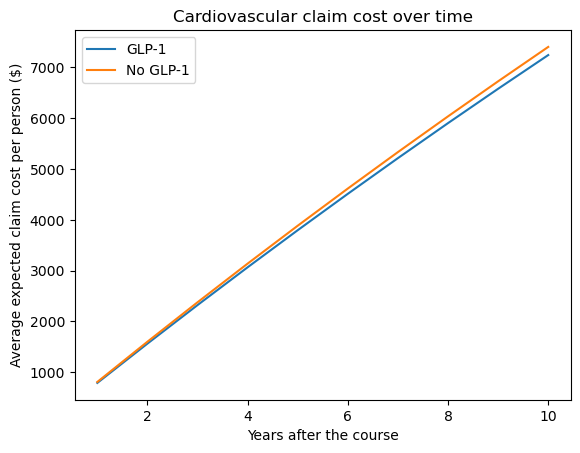

In [19]:
import matplotlib.pyplot as plt
years = np.arange(1, 11)
cost_glp1   = [np.mean(cardiovascular_cost*(1-np.exp(-h*t))) for t in years]
cost_noglp1 = [np.mean(cardiovascular_cost*(1-np.exp(-h_noglp*t))) for t in years]

plt.plot(years, cost_glp1, label='GLP-1')
plt.plot(years, cost_noglp1, label='No GLP-1')
plt.xlabel('Years after the course')
plt.ylabel('Average expected claim cost per person ($)')
plt.title('Cardiovascular claim cost over time')
plt.legend()
plt.show()

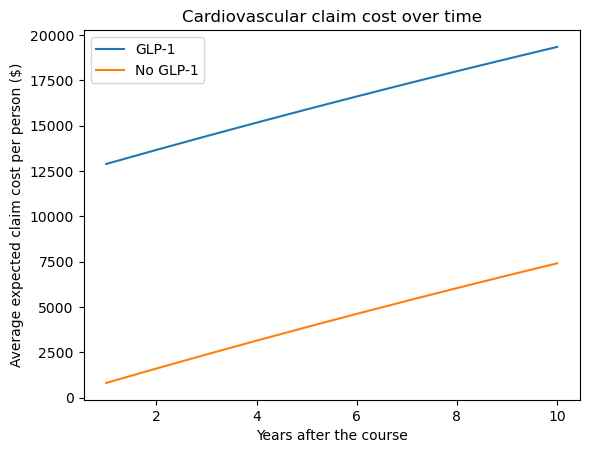

In [20]:
years = np.arange(1, 11)
cost_glp1  =[np.mean(cardiovascular_cost*(1-np.exp(-h*t))) + (drug_cost*duration).mean() for t in years]
cost_noglp1 = [np.mean(cardiovascular_cost*(1-np.exp(-h_noglp*t))) for t in years]

plt.plot(years, cost_glp1, label='GLP-1')
plt.plot(years, cost_noglp1, label='No GLP-1')
plt.xlabel('Years after the course')
plt.ylabel('Average expected claim cost per person ($)')
plt.title('Cardiovascular claim cost over time')
plt.legend()
plt.show()

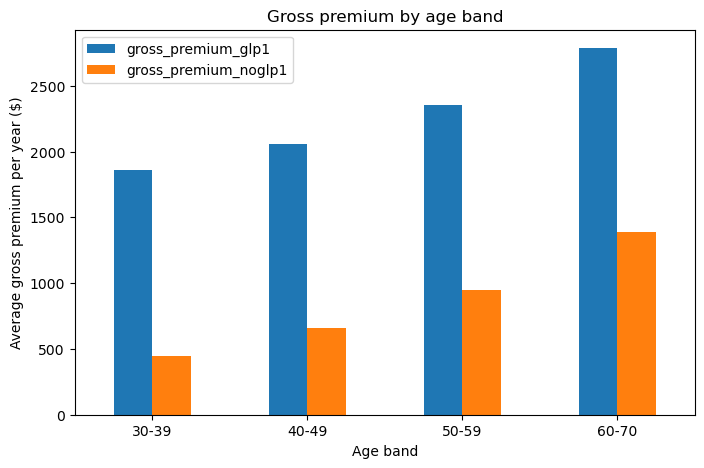

In [21]:
import matplotlib.pyplot as plt

df['age_band'] = pd.cut(df['age'], bins=[29, 39, 49, 59, 70],labels=['30-39', '40-49', '50-59', '60-70'])

avg = df.groupby('age_band', observed=True)[['gross_premium_glp1', 'gross_premium_noglp1']].mean()

avg.plot(kind='bar', figsize=(8, 5))
plt.xlabel('Age band')
plt.ylabel('Average gross premium per year ($)')
plt.title('Gross premium by age band')
plt.xticks(rotation=0)
plt.show()

In [26]:
[np.mean(gross_premium),np.mean(gross_premium_nonglp1),np.mean(ind_cardio_cost_10years_glp1),np.mean(ind_cardio_cost_10years_noglp1)]

[np.float64(2275.2718601113766),
 np.float64(871.1444011962833),
 np.float64(7244.429936881511),
 np.float64(7404.727410168406)]